# TinyCD – extended test on 32 before/after pairs

Extension of `tinycd_demo.ipynb` (that notebook is unchanged). Same pretrained model (`levir_best.pth`, 285,128 parameters), **no retraining, no fine-tuning, no threshold tuning** – official preprocessing and the official 0.5 cut-off.

**What is tested** – 32 pairs in four groups, each with a different level of trust. *Please read the tier column before reading any number:*

| Tier | Group | Pairs | Ground truth | What the numbers mean |
|---|---|---|---|---|
| **A** | Aerial building change – LEVIR-CD test tiles (the model's home domain) | 12 (10 change + 2 no-change) | official, pixel-accurate | **valid F1 / IoU** (small sample: see the confidence interval) |
| **B** | Aerial – SYSU-CD test tiles | 4 | official but coarse region polygons | valid F1 / IoU, but a **cross-dataset** domain-shift test |
| **C** | Ordinary photos – MagicBrush (real COCO photos: vehicles, people, everyday objects, outdoor scenes; the "after" is an AI edit) | 12 | only the *region the annotator allowed to be edited* (a loose superset of the true change) | **indicative only – not valid F1/IoU** |
| **D** | Real before/after photos – Wikimedia Commons (landmarks, buildings, aerial drone) | 4 | **none** | **qualitative only – no F1/IoU is computed** |

Honest framing: TinyCD was trained **only** on aerial building change between *registered* images. Groups C and D are stress tests of what happens outside that domain, not a claim that it supports them.
Licence reminder: TinyCD code/weights are non-commercial/research-only; LEVIR-CD is academic-only; each pair's source and licence is in `extended_test/pairs_manifest.csv`.

## 1. Setup – environment, official code, checkpoint, data

In [1]:
import sys, subprocess, hashlib, json, time
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd()/'scripts').exists() else Path.cwd().parent
REPO = ROOT/'third_party'/'Tiny_model_4_CD'
if not REPO.exists():                                   # official implementation
    subprocess.run(['git','clone','--depth','1','https://github.com/AndreaCodegoni/Tiny_model_4_CD.git',str(REPO)], check=True)
sys.path.insert(0, str(ROOT/'scripts'))
import cdcommon as C, extended_eval as E

CKPT = REPO/'pretrained_models'/'levir_best.pth'
sha = hashlib.sha256(CKPT.read_bytes()).hexdigest()
print('checkpoint', CKPT.relative_to(ROOT), f'{CKPT.stat().st_size/1e6:.2f} MB | sha256 matches recorded value:',
      sha == '743645b87199c96bd0c3271ae5df6f0918b3f1d84618dfb9396843ca08ee4a3e')
print('official commit', subprocess.run(['git','-C',str(REPO),'rev-parse','--short','HEAD'],capture_output=True,text=True).stdout.strip())
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device', device, torch.cuda.get_device_name(0) if device=='cuda' else '')

if not (ROOT/'extended_test'/'pairs_manifest.csv').exists():   # one-off download of the pairs (~300 MB, mostly cached range requests)
    subprocess.run([sys.executable, str(ROOT/'scripts'/'build_extended_set.py')], check=True)
print('pairs on disk:', len(list((ROOT/'extended_test'/'inputs').rglob('*_A.png'))))

checkpoint third_party/Tiny_model_4_CD/pretrained_models/levir_best.pth 1.28 MB | sha256 matches recorded value: True
official commit 1696827
torch 2.7.1+cu118 | device cuda NVIDIA GeForce GTX 1080 Ti
pairs on disk: 32


## 2. The pairs, their sources and licences
(Full table with source references: `extended_test/pairs_manifest.csv`.)

In [2]:
man = pd.read_csv(ROOT/'extended_test'/'pairs_manifest.csv')
display(man.groupby(['group','category']).agg(pairs=('pair_id','count'), licence=('licence','first'), gt_type=('gt_type','first')).reset_index())
pd.set_option('display.max_colwidth', 70); pd.set_option('display.width', 220)
display(man[man.group.isin(['photo_real'])][['pair_id','category','source_reference','licence','attribution','notes']])

,group,category,pairs,licence,gt_type
0,aerial_levir,aerial-building-change,10,academic use only (LEVIR-CD terms),official
1,aerial_levir,aerial-no-change,2,academic use only (LEVIR-CD terms),official
2,aerial_sysu,aerial-cross-dataset,4,not stated by authors,official (coarse region polygons)
3,photo_edit,everyday-objects,4,CC BY 4.0,proxy (editor's mask)
4,photo_edit,outdoor-scenes,2,CC BY 4.0,proxy (editor's mask)
5,photo_edit,people,3,CC BY 4.0,proxy (editor's mask)
6,photo_edit,vehicles,3,CC BY 4.0,proxy (editor's mask)
7,photo_real,buildings,1,CC BY 2.0,none
8,photo_real,buildings-aerial,1,CC BY-SA 4.0,none
9,photo_real,landmarks,2,CC BY-SA 4.0,none


,pair_id,category,source_reference,licence,attribution,notes
28,wm_landmark_notredame,landmarks,https://commons.wikimedia.org/wiki/File:Notre_Dame-before-the-fire...,CC BY-SA 4.0,Zuffe y Louis HG,different camera position & weather; NOT registered
29,wm_landmark_fawley,landmarks,https://commons.wikimedia.org/wiki/File:Views_before_and_after_dem...,CC BY-SA 4.0,ITookSomePhotos,same viewpoint; chimney removed; roughly registered
30,wm_building_sydenham,buildings,https://commons.wikimedia.org/wiki/File:Sydenham_Heritage_Church_B...,CC BY 2.0,Gobeirne,similar viewpoint; church demolished; lighting differs
31,wm_building_bigmill,buildings-aerial,https://commons.wikimedia.org/wiki/File:Big_Mill_Before_and_After_...,CC BY-SA 4.0,Gkbediako,drone view; collage order is after|before so halves are swapped (b...


## 3. Run TinyCD on every pair
Preprocessing is the official one (RGB/255, ImageNet mean/std, sigmoid output, threshold 0.5). **One documented deviation:** aerial tiles are fed at their native 256×256; photos (groups C, D) are resized so the long side is 512 px (sides multiples of 8), because the model has only ever seen 256×256 aerial tiles. Two simple baselines run on the same inputs: absolute RGB difference with **Otsu** threshold (per image) and with a **fixed threshold (103) chosen on the LEVIR validation set**, never on these pairs.
Outputs are saved per pair in `extended_test/outputs/<group>/<category>/` (`*_prob.png`, `*_mask.png`, `*_baseline_*.png`, `*_compare.png`).

In [3]:
results = E.run_all(device)
recs, cats = E.write_tables(results)
E.save_pair_figures(results)
print(len(results), 'pairs processed | median latency per pair (batch 1, incl. small CUDA sync): %.1f ms' % np.median([r['latency_ms'] for r in recs]))
print('outputs ->', ROOT/'extended_test'/'outputs')

/home/administrator/Desktop/image difference/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/administrator/Desktop/image difference/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


32 pairs processed | median latency per pair (batch 1, incl. small CUDA sync): 35.4 ms
outputs -> /home/administrator/Desktop/image difference/extended_test/outputs


## 4. Visual results – same 6-column format as the first notebook
Image A · Image B · ground truth (if any) · TinyCD probability · TinyCD mask (> 0.5) · RGB-difference Otsu baseline.

### 4A. Tier A – aerial building change, LEVIR-CD (in-domain, official ground truth)

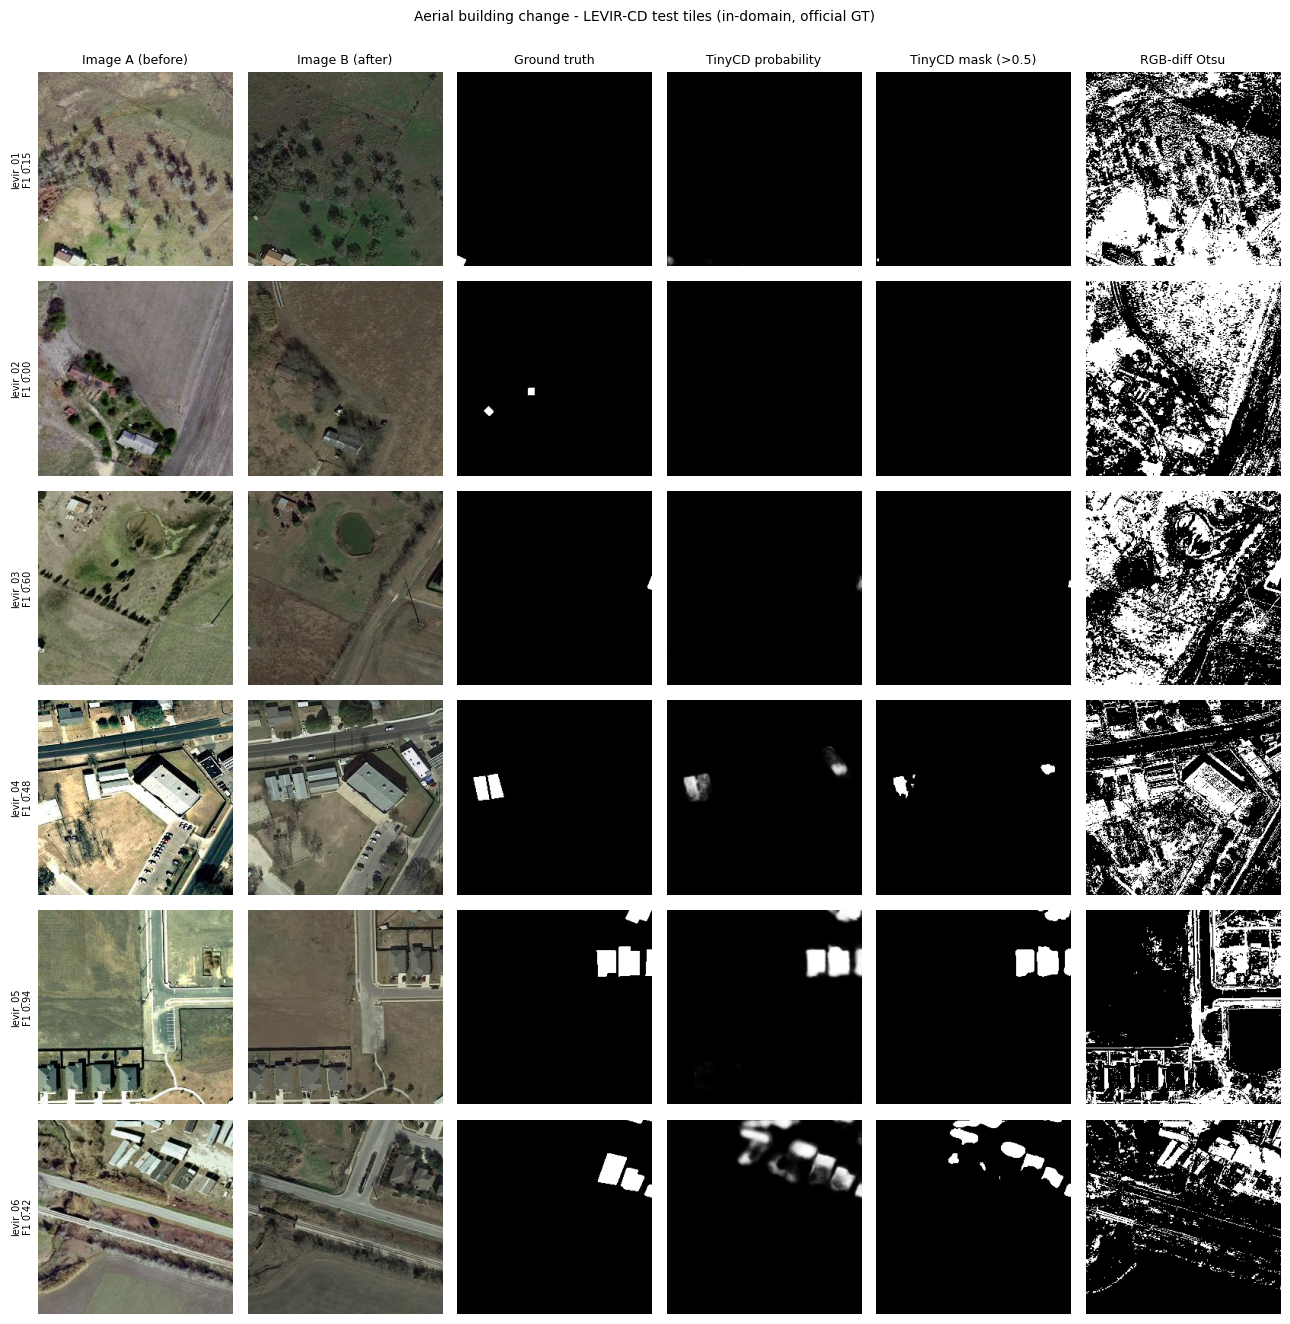

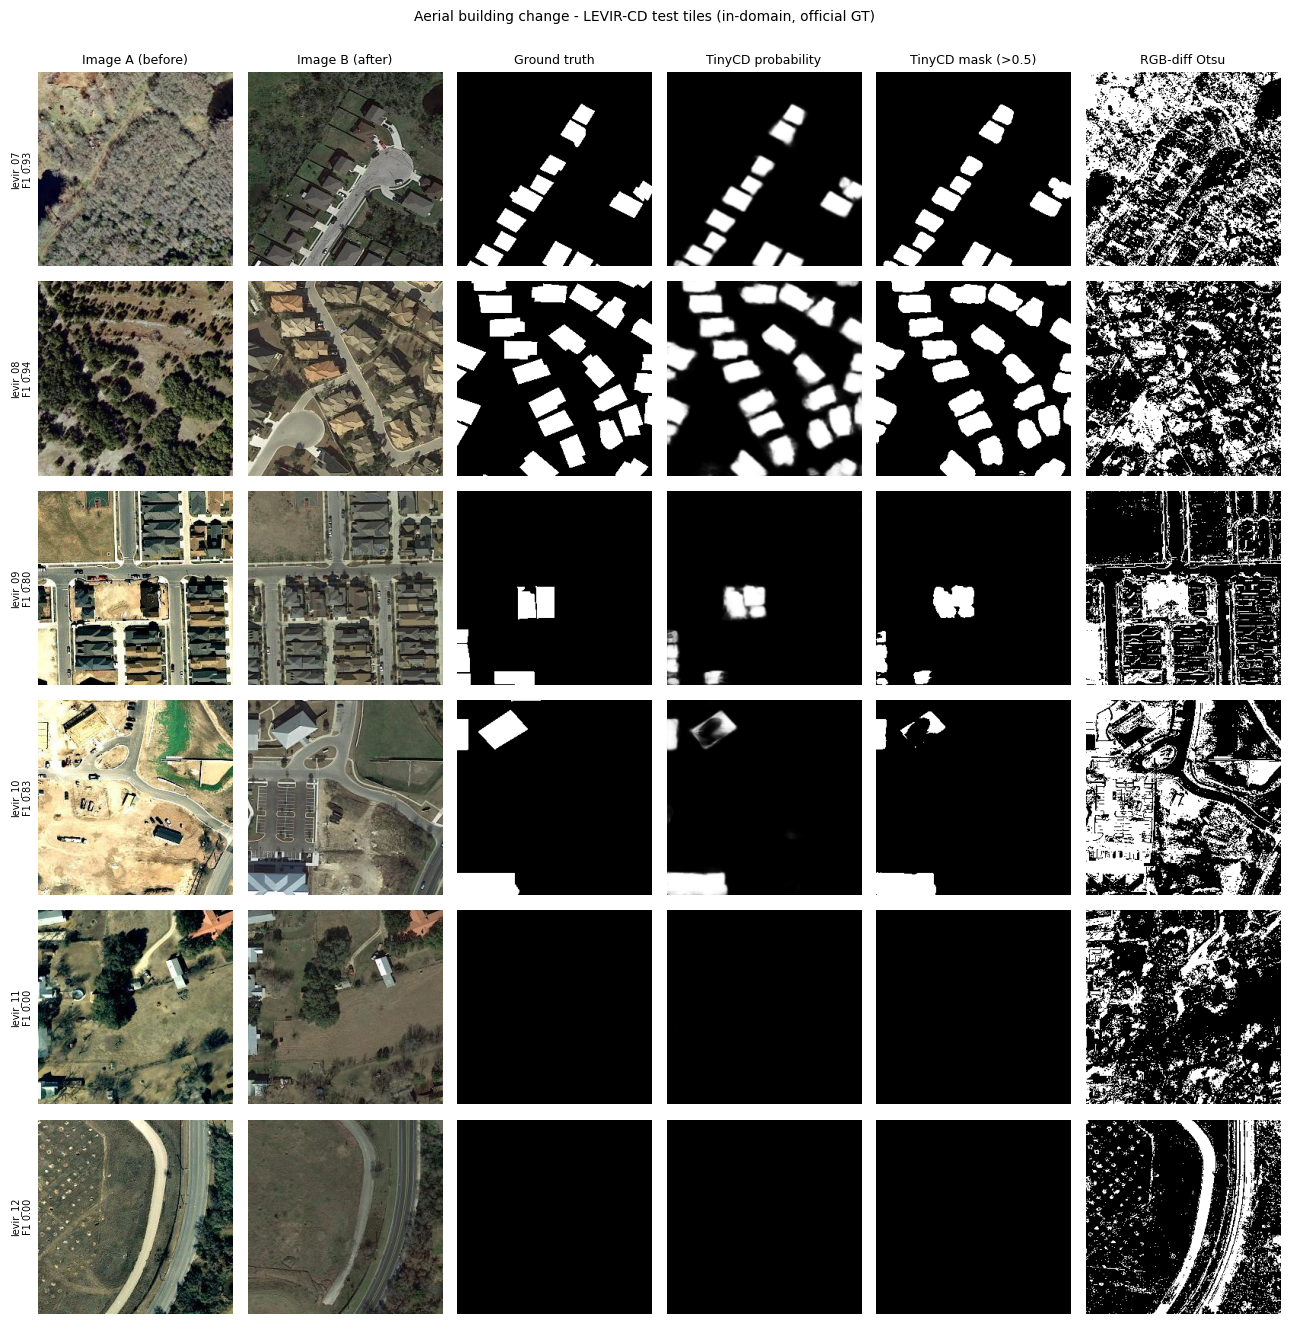

In [4]:
ids = [r['pair_id'] for r in recs if r['group']=='aerial_levir']
plt.close(E.figure(results, 'aerial_levir', ids[:6])); fig = E.figure(results, 'aerial_levir', ids[:6]); plt.show()
fig = E.figure(results, 'aerial_levir', ids[6:]); plt.show()

### 4B. Tier B – aerial, SYSU-CD (cross-dataset, coarse official ground truth)

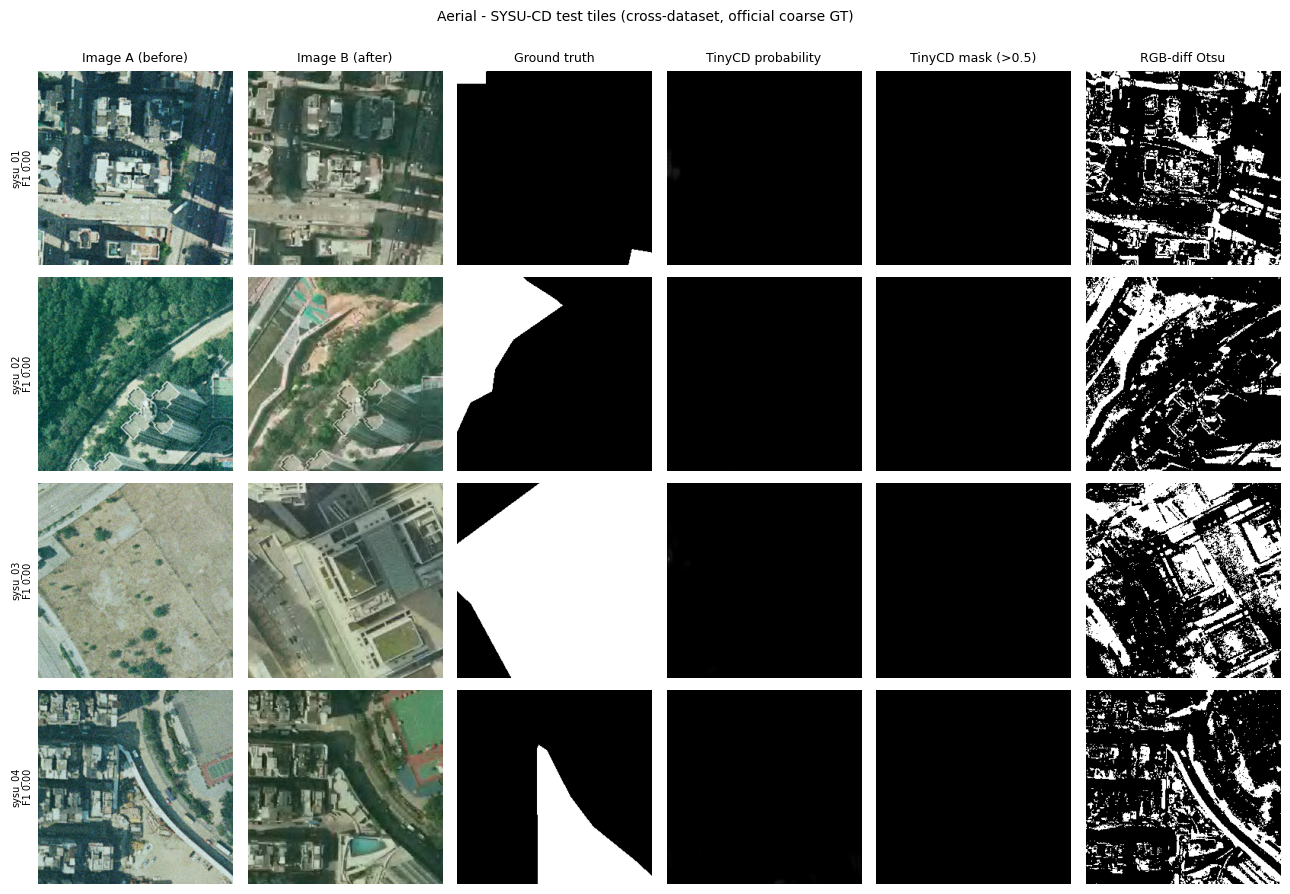

In [5]:
fig = E.figure(results, 'aerial_sysu'); plt.show()

### 4C. Tier C – ordinary photos with AI-made edits (MagicBrush) – **proxy ground truth, indicative only**
The white area in the *Ground truth* column is only the region the annotator was allowed to edit (I verified numerically that 78–99 % of strongly changed pixels fall inside it, but it is much larger than the real change). Pixels outside it are guaranteed unchanged.

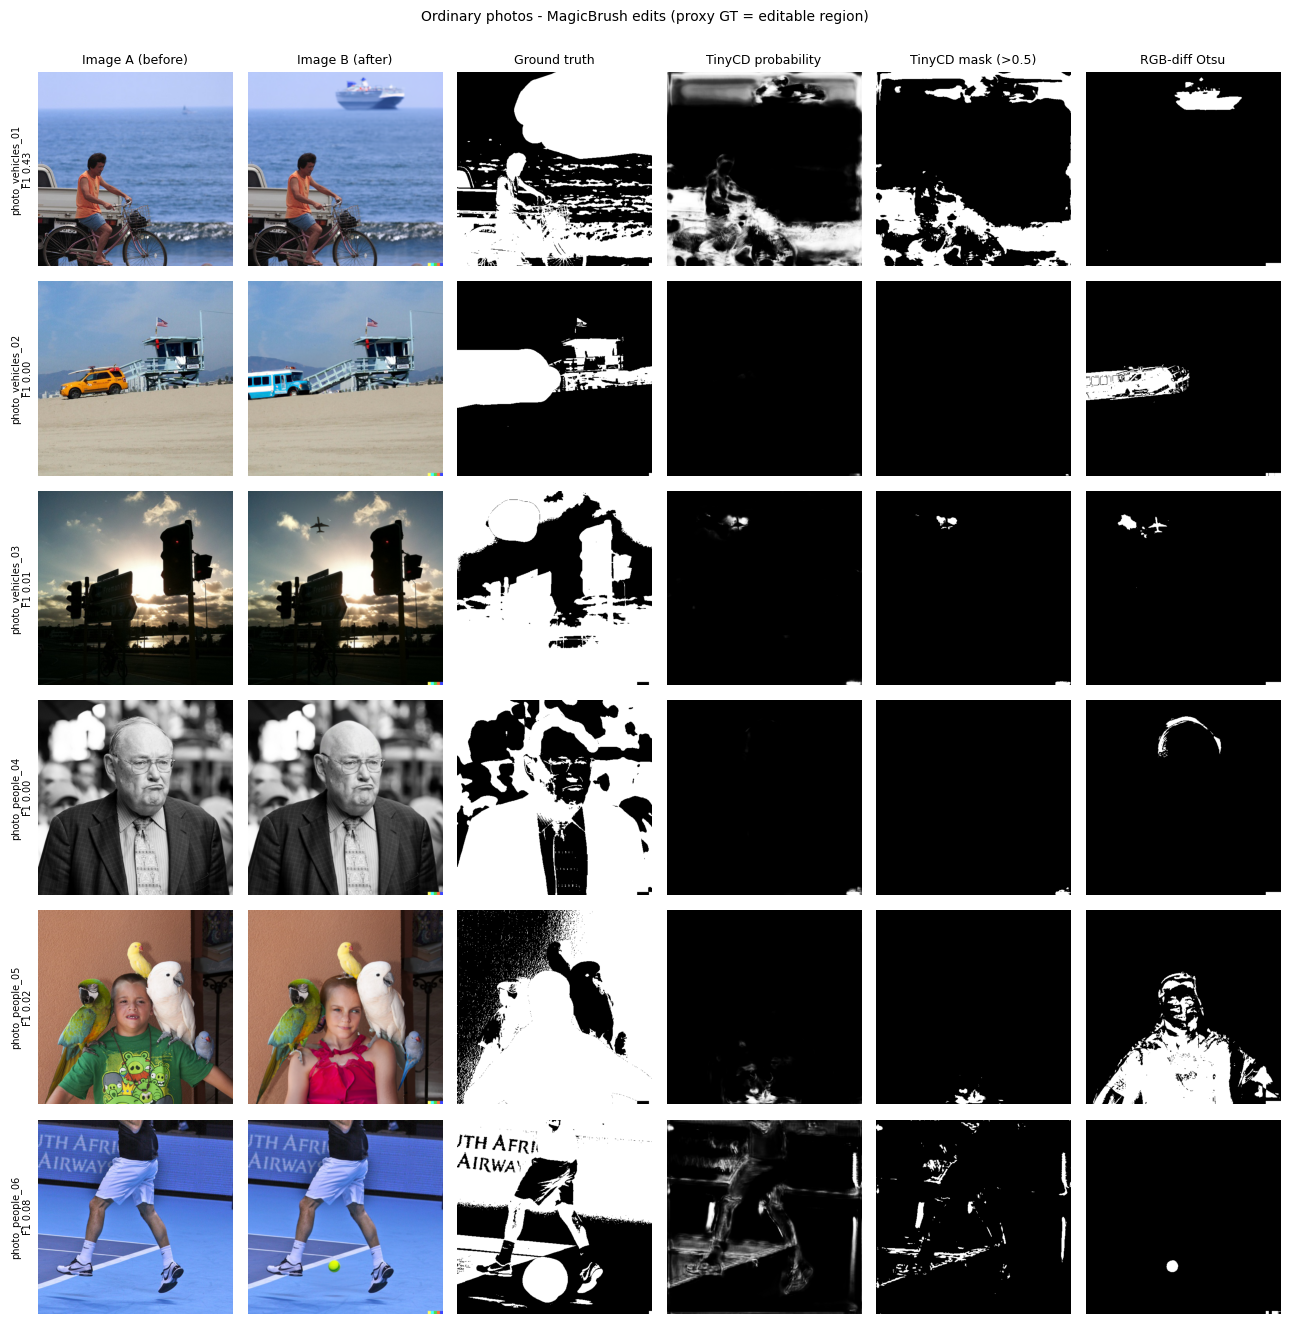

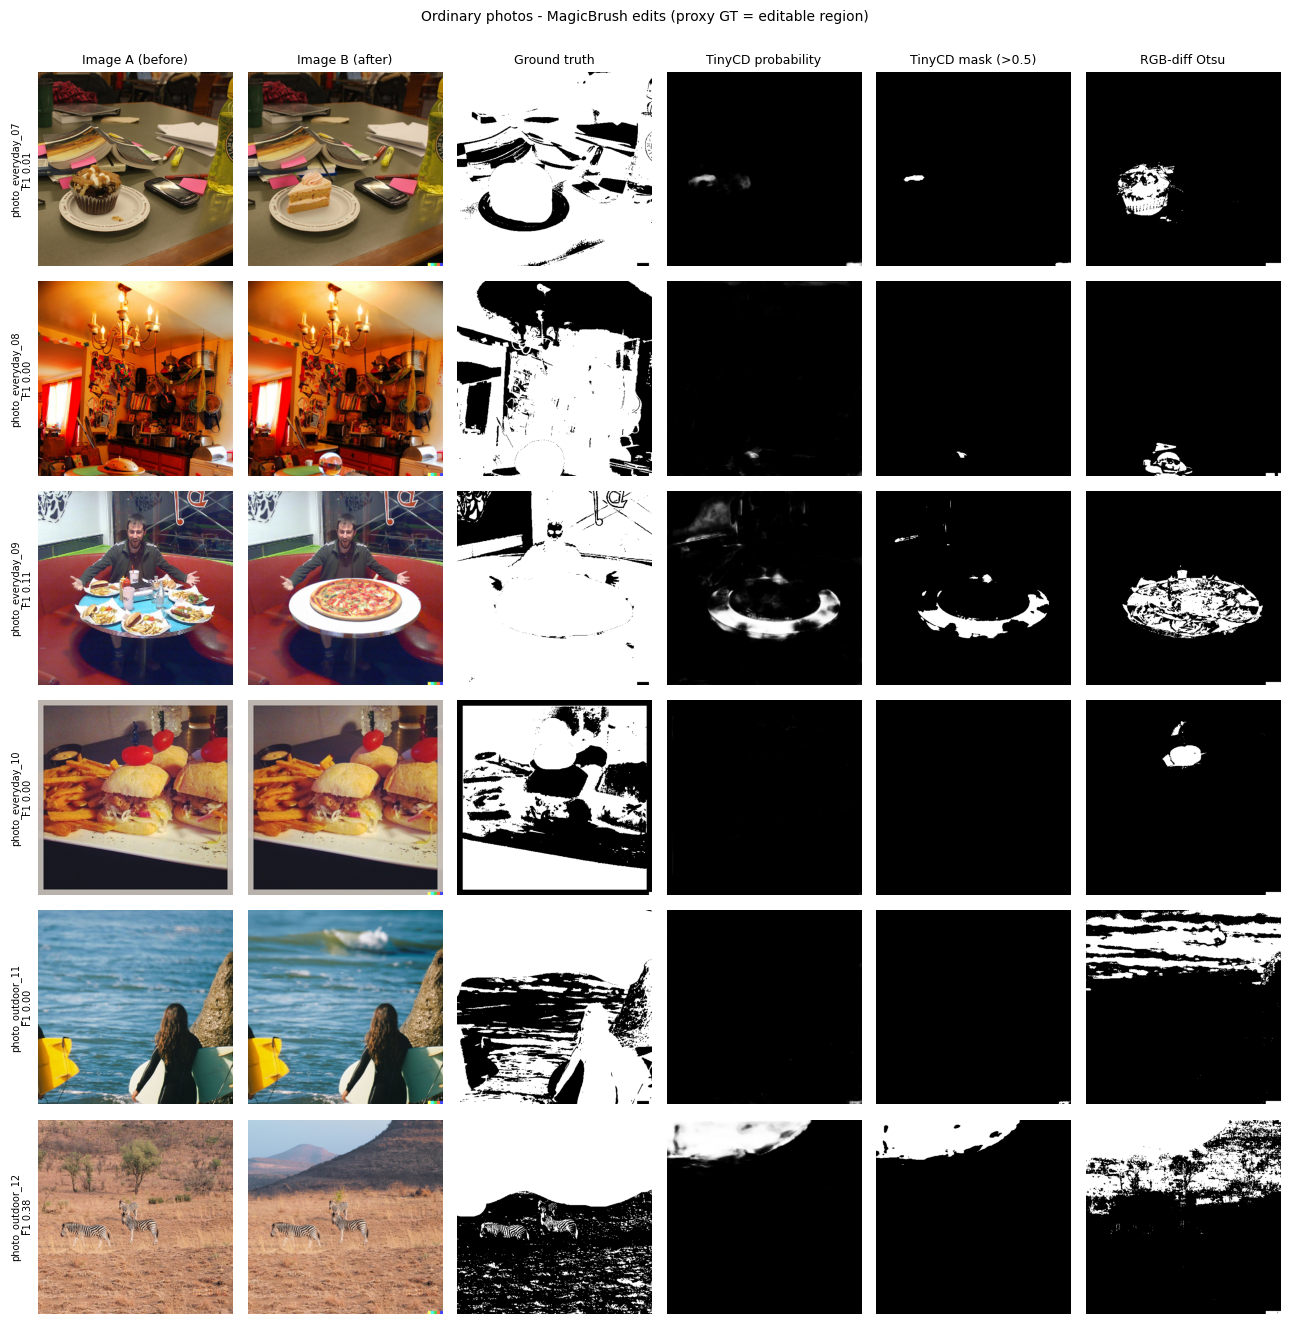

In [6]:
ids = [r['pair_id'] for r in recs if r['group']=='photo_edit']
fig = E.figure(results, 'photo_edit', ids[:6]); plt.show()
fig = E.figure(results, 'photo_edit', ids[6:]); plt.show()

### 4D. Tier D – real before/after photos (Wikimedia Commons) – **qualitative only, no ground truth**
Landmarks and buildings, not registered (different camera position, weather or height), exactly the situation TinyCD's authors say it is not built for.

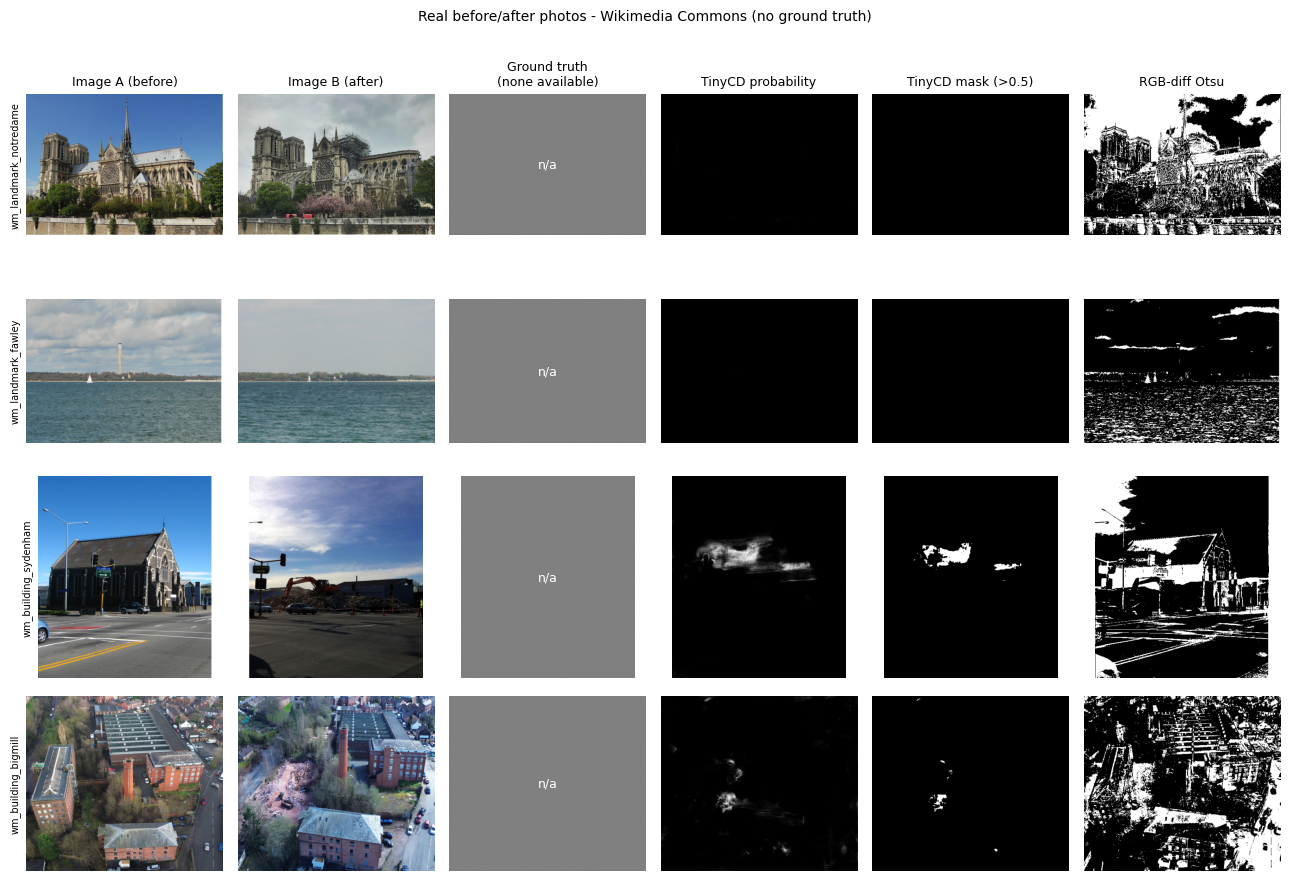

In [7]:
fig = E.figure(results, 'photo_real'); plt.show()

## 5. Metrics – what is valid and what is not

### 5.1 Per-category results (`extended_test/results_per_category.csv`)
Pooled over all pixels of the pairs in the category. **Only tiers A and B are valid F1/IoU evaluations.** Tier C columns are shown for completeness and are *not* valid – see the warning below the table. Tier D has no metrics by design. A category with no labelled change pixels (the 2 no-change tiles) has no defined F1 – it shows ‘–’ and we count false alarms instead (section 5.2).

In [8]:
cat = pd.DataFrame(cats)
show = cat[['tier','category','n_pairs','valid_f1_iou','tinycd_precision','tinycd_recall','tinycd_f1','tinycd_iou','otsu_f1','fixed_f1','mean_pred_change_pct']].copy()
show.columns = ['tier','category','pairs','valid F1/IoU?','TinyCD P','TinyCD R','TinyCD F1','TinyCD IoU','Otsu F1','fixed-thr F1','TinyCD mean % pixels flagged']
display(show.style.format(precision=3, na_rep='–').apply(lambda r: ['background-color:#e6f4ea' if r['valid F1/IoU?'].startswith('yes') else ('background-color:#fff4e5' if r['valid F1/IoU?'].startswith('no - proxy') else 'background-color:#f1f1f1')]*len(r), axis=1))

,tier,category,pairs,valid F1/IoU?,TinyCD P,TinyCD R,TinyCD F1,TinyCD IoU,Otsu F1,fixed-thr F1,TinyCD mean % pixels flagged
0,"A: official GT, in-domain",aerial-building-change,10,yes,0.897,0.854,0.875,0.777,0.124,0.162,6.090
1,"A: official GT, in-domain",aerial-no-change,2,yes,–,–,–,–,–,–,0.000
2,"B: official GT, cross-dataset",aerial-cross-dataset,4,yes (cross-dataset),0.000,0.000,0.000,0.000,0.454,0.197,0.000
3,C: proxy GT (indicative),vehicles,3,no - proxy only,0.701,0.122,0.207,0.116,0.116,0.050,8.550
4,C: proxy GT (indicative),people,3,no - proxy only,0.658,0.016,0.032,0.016,0.223,0.034,1.540
5,C: proxy GT (indicative),everyday-objects,4,no - proxy only,0.954,0.018,0.036,0.018,0.121,0.039,1.410
6,C: proxy GT (indicative),outdoor-scenes,2,no - proxy only,0.995,0.100,0.181,0.100,0.584,0.019,5.860
7,D: no GT (qualitative),landmarks,2,no - no GT,–,–,–,–,–,–,0.000
8,D: no GT (qualitative),buildings,1,no - no GT,–,–,–,–,–,–,1.750
9,D: no GT (qualitative),buildings-aerial,1,no - no GT,–,–,–,–,–,–,0.320


> **Do not read tier C's F1/IoU as accuracy.** The "ground truth" there is a loose editable region (often 50–85 % of the picture) while the real edit is small, so recall-against-region is tiny by construction and the Otsu baseline "wins" F1 in some rows simply because it paints a lot of pixels. A fairer tier-C number is the false-alarm rate on pixels guaranteed unchanged (next table).

In [9]:
c = cat[cat.group=='photo_edit'][['category','n_pairs','tinycd_false_alarm_outside_region_pct','otsu_false_alarm_outside_region_pct','mean_pred_change_pct']]
c.columns = ['category','pairs','TinyCD false alarms outside editable region (% of those pixels)','Otsu false alarms outside region (%)','TinyCD % of image flagged']
display(c.style.format(precision=2))

,category,pairs,TinyCD false alarms outside editable region (% of those pixels),Otsu false alarms outside region (%),TinyCD % of image flagged
3,vehicles,3,5.94,0.23,8.55
4,people,3,1.21,0.30,1.54
5,everyday-objects,4,0.47,0.66,1.41
6,outdoor-scenes,2,0.09,0.51,5.86


### 5.2 Tier A: how much can we trust 12 pairs? (bootstrap over pairs, 95 %)

In [10]:
ci = E.bootstrap_group_f1(recs, 'aerial_levir')
a = cat[cat.group=='aerial_levir']
tp = sum(r['tinycd_TP'] for r in recs if r['group']=='aerial_levir'); fp = sum(r['tinycd_FP'] for r in recs if r['group']=='aerial_levir')
fn = sum(r['tinycd_FN'] for r in recs if r['group']=='aerial_levir'); tn = sum(r['tinycd_TN'] for r in recs if r['group']=='aerial_levir')
s = C.scores(tp, fp, fn, tn)
print(f"TinyCD on these 12 LEVIR tiles (pooled): F1 {s['f1']:.3f}  [95% CI {ci['f1'][0]:.3f}-{ci['f1'][1]:.3f}]   IoU {s['iou']:.3f} [{ci['iou'][0]:.3f}-{ci['iou'][1]:.3f}]   P {s['precision']:.3f}   R {s['recall']:.3f}")
print('For reference, the full 2,048-pair LEVIR test (earlier run): F1 0.9107 [0.9063-0.9147]. The wide interval here is the price of a 12-pair sample.')
nc = [r for r in recs if r['group']=='aerial_levir' and r['gt_pct']==0]
print('no-change pairs:', len(nc), '| pairs with any predicted change pixel:', sum(r['pred_change_pct']>0 for r in nc), '(TinyCD) vs', sum(r['otsu_FP']>0 for r in nc), '(RGB-diff Otsu)')

TinyCD on these 12 LEVIR tiles (pooled): F1 0.875  [95% CI 0.687-0.927]   IoU 0.777 [0.524-0.864]   P 0.897   R 0.854
For reference, the full 2,048-pair LEVIR test (earlier run): F1 0.9107 [0.9063-0.9147]. The wide interval here is the price of a 12-pair sample.
no-change pairs: 2 | pairs with any predicted change pixel: 0 (TinyCD) vs 2 (RGB-diff Otsu)


### 5.3 Per-pair table (`extended_test/results_per_pair.csv`)

In [11]:
d = pd.DataFrame(recs)
cols = ['pair_id','tier','category','infer_size','gt_pct','pred_change_pct','max_prob','tinycd_precision','tinycd_recall','tinycd_f1','tinycd_iou','otsu_f1','latency_ms']
display(d[cols].style.format(precision=3, na_rep='–'))

,pair_id,tier,category,infer_size,gt_pct,pred_change_pct,max_prob,tinycd_precision,tinycd_recall,tinycd_f1,tinycd_iou,otsu_f1,latency_ms
0,levir_01,"A: official GT, in-domain",aerial-building-change,256x256,0.191,0.015,0.577,1.000,0.080,0.148,0.080,0.003,21.600
1,levir_02,"A: official GT, in-domain",aerial-building-change,256x256,0.282,0.000,0.005,0.000,0.000,0.000,0.000,0.004,21.900
2,levir_03,"A: official GT, in-domain",aerial-building-change,256x256,0.102,0.044,0.666,1.000,0.433,0.604,0.433,0.001,27.700
3,levir_04,"A: official GT, in-domain",aerial-building-change,256x256,1.460,0.853,0.955,0.648,0.378,0.478,0.314,0.023,22.600
4,levir_05,"A: official GT, in-domain",aerial-building-change,256x256,3.880,3.825,1.000,0.950,0.936,0.943,0.892,0.148,21.800
5,levir_06,"A: official GT, in-domain",aerial-building-change,256x256,2.939,4.214,0.997,0.360,0.516,0.424,0.269,0.126,21.900
6,levir_07,"A: official GT, in-domain",aerial-building-change,256x256,11.015,10.994,1.000,0.933,0.931,0.932,0.873,0.083,21.800
7,levir_08,"A: official GT, in-domain",aerial-building-change,256x256,31.099,31.355,1.000,0.937,0.945,0.941,0.889,0.398,21.900
8,levir_09,"A: official GT, in-domain",aerial-building-change,256x256,5.898,4.510,1.000,0.918,0.702,0.795,0.660,0.310,21.900
9,levir_10,"A: official GT, in-domain",aerial-building-change,256x256,7.060,5.058,1.000,0.996,0.714,0.831,0.712,0.097,21.900


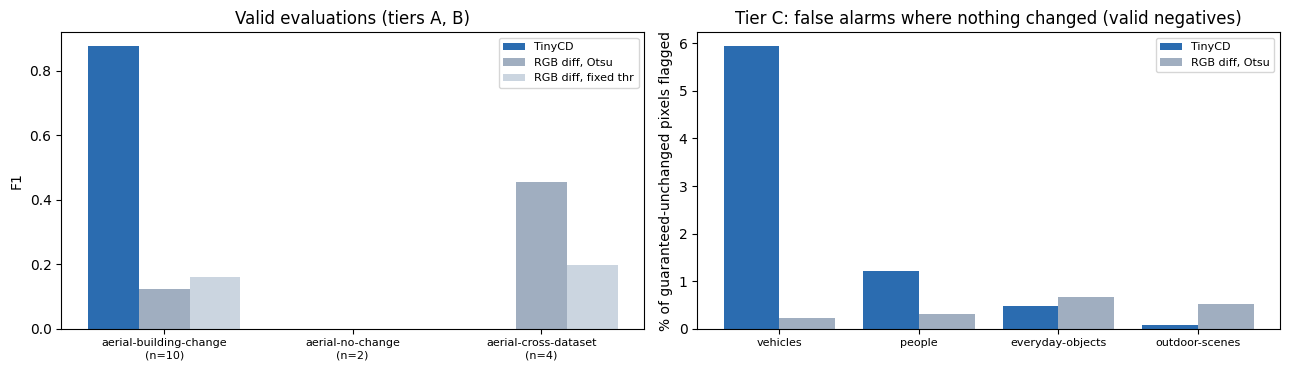

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
v = cat[cat.group.isin(['aerial_levir','aerial_sysu'])]; v = v[v.n_pairs>0]
x = np.arange(len(v)); w = 0.27
ax[0].bar(x-w, v.tinycd_f1, w, label='TinyCD', color='#2b6cb0'); ax[0].bar(x, v.otsu_f1, w, label='RGB diff, Otsu', color='#a0aec0'); ax[0].bar(x+w, v.fixed_f1, w, label='RGB diff, fixed thr', color='#cbd5e0')
ax[0].set_xticks(x); ax[0].set_xticklabels([f"{c}\n(n={n})" for c, n in zip(v.category, v.n_pairs)], fontsize=8); ax[0].set_ylabel('F1'); ax[0].set_title('Valid evaluations (tiers A, B)'); ax[0].legend(fontsize=8)
p = cat[cat.group=='photo_edit']
ax[1].bar(np.arange(len(p))-0.2, p.tinycd_false_alarm_outside_region_pct, 0.4, label='TinyCD', color='#2b6cb0'); ax[1].bar(np.arange(len(p))+0.2, p.otsu_false_alarm_outside_region_pct, 0.4, label='RGB diff, Otsu', color='#a0aec0')
ax[1].set_xticks(np.arange(len(p))); ax[1].set_xticklabels(p.category, fontsize=8); ax[1].set_ylabel('% of guaranteed-unchanged pixels flagged'); ax[1].set_title('Tier C: false alarms where nothing changed (valid negatives)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Failures and limitations (observed in this run)

In [13]:
rows = []
for r in recs:
    g = r['group']
    if g == 'aerial_levir' and r['gt_pct'] > 0:
        if r['tinycd_recall'] < 0.25: rows.append((r['pair_id'], 'A (valid)', 'MISSED – recall %.2f, only %.2f%% of the tile flagged vs %.2f%% labelled changed' % (r['tinycd_recall'], r['pred_change_pct'], r['gt_pct'])))
        elif r['tinycd_precision'] < 0.5: rows.append((r['pair_id'], 'A (valid)', 'FALSE ALARMS – precision %.2f (flagged %.2f%% vs %.2f%% labelled)' % (r['tinycd_precision'], r['pred_change_pct'], r['gt_pct'])))
    if g == 'aerial_sysu': rows.append((r['pair_id'], 'B (valid, cross-dataset)', 'SILENT – flagged %.2f%% of the tile; labelled change %.1f%%; max probability %.2f' % (r['pred_change_pct'], r['gt_pct'], r['max_prob'])))
    if g == 'photo_edit' and r['pred_change_pct'] < 1: rows.append((r['pair_id'], 'C (proxy)', 'NOT DETECTED – %.2f%% of the image flagged (an edit exists, see the RGB-diff column)' % r['pred_change_pct']))
    if g == 'photo_real': rows.append((r['pair_id'], 'D (qualitative)', 'flagged %.2f%% of the image, max probability %.2f – judge by eye (see 4D)' % (r['pred_change_pct'], r['max_prob'])))
fail = pd.DataFrame(rows, columns=['pair','tier','observation'])
fail.to_csv(ROOT/'extended_test'/'failure_log_auto.csv', index=False)
pd.set_option('display.max_colwidth', 140); display(fail)

,pair,tier,observation
0,levir_01,A (valid),"MISSED – recall 0.08, only 0.01% of the tile flagged vs 0.19% labelled changed"
1,levir_02,A (valid),"MISSED – recall 0.00, only 0.00% of the tile flagged vs 0.28% labelled changed"
2,levir_06,A (valid),FALSE ALARMS – precision 0.36 (flagged 4.21% vs 2.94% labelled)
3,sysu_01,"B (valid, cross-dataset)",SILENT – flagged 0.00% of the tile; labelled change 1.9%; max probability 0.18
4,sysu_02,"B (valid, cross-dataset)",SILENT – flagged 0.00% of the tile; labelled change 21.0%; max probability 0.01
5,sysu_03,"B (valid, cross-dataset)",SILENT – flagged 0.00% of the tile; labelled change 86.5%; max probability 0.26
6,sysu_04,"B (valid, cross-dataset)",SILENT – flagged 0.00% of the tile; labelled change 19.8%; max probability 0.09
7,photo_vehicles_02,C (proxy),"NOT DETECTED – 0.01% of the image flagged (an edit exists, see the RGB-diff column)"
8,photo_vehicles_03,C (proxy),"NOT DETECTED – 0.42% of the image flagged (an edit exists, see the RGB-diff column)"
9,photo_people_04,C (proxy),"NOT DETECTED – 0.16% of the image flagged (an edit exists, see the RGB-diff column)"


### Reading the failures
1. **Tiny aerial changes are missed (tier A).** The labelled change in `levir_01`/`levir_02` is 0.1–0.3 % of the tile (a few pixels): TinyCD flags nothing or a sliver. This matches the full-test analysis (objects under 50 px are found ≈ 20 % of the time).
2. **Look-alike construction causes false alarms (tier A).** In `levir_06` the model flags extra buildings that the annotators did not mark – precision drops to ≈ 0.36 although the scene is in-domain.
3. **Cross-dataset collapse (tier B).** On all four SYSU-CD tiles TinyCD outputs essentially nothing (max probability ≈ 0.01–0.26), whereas the plain RGB baseline scores higher *because SYSU's labels are huge coarse regions*. Neither result says TinyCD is "bad at SYSU buildings"; it says the LEVIR-trained weights are not calibrated for that imagery and that label style differs.
4. **Ordinary photos: mostly not detected (tier C).** Adding a plane, changing a person or swapping a cupcake is largely invisible to TinyCD (8 of 12 pairs have <1 % of the image flagged); the pizza edge in `photo_everyday_09` and the new mountain area in `photo_outdoor_12` are partial hits, but elsewhere it often fires on the wrong thing (a large part of the sea/sky in `photo_vehicles_01`, extra background in `photo_outdoor_12`). A learned *aerial-building* detector has no notion of "a new object appeared in a street/indoor photo". Note that the simple RGB-difference baseline isolates these edits well, because MagicBrush edits leave all other pixels identical – **this is not a fair proxy for real-world change detection**, where lighting, shadows and camera shake dominate.
5. **Real before/after photos (tier D).** The Fawley chimney removal (same viewpoint, large clear change) is **not detected at all**; Notre-Dame (spire gone, scaffolding) is also not detected; the demolished church and the drone-view mill give small scattered blobs that follow lighting/viewpoint differences rather than the demolished structures. No quantitative claim is made – there is no ground truth.

### Limitations of this test (please keep with any numbers above)
* **Small samples:** 12 + 4 pairs with valid ground truth. The 12-pair F1 has a wide confidence interval; the authoritative in-domain number is the 2,048-pair run (F1 91.07 vs paper 91.05).
* **Tier C ground truth is a loose region**, and its "after" images are AI edits, not natural change. Tier D is only 4 pairs with no labels.
* **Resizing photos to 512 px is a deviation** from the official 256×256 tiles; other scales might change the photo results, but no scale makes TinyCD an ordinary-photo change detector.
* **No registration:** the paper itself assumes aligned images; groups C (aligned) and D (partly unaligned) were not corrected.
* **Licences:** TinyCD code/weights non-commercial/research only; LEVIR-CD academic only; SYSU-CD no licence stated; MagicBrush CC BY 4.0; Wikimedia items CC BY / CC BY-SA (attribution in the manifest).
* **Next step if photos/landmarks are the real client need:** collect a small labelled before/after set from that domain and evaluate this same checkpoint first, then consider fine-tuning – or choose a model trained for ordinary-photo change detection.

## 7. Where everything was saved

In [14]:
tree = []
for p in sorted((ROOT/'extended_test').rglob('*')):
    if p.is_file() and p.suffix in ('.csv','.md') or (p.is_dir() and p.parent.name in ('inputs','outputs')):
        tree.append(str(p.relative_to(ROOT)) + ('/' if p.is_dir() else ''))
print('\n'.join(tree))
print()
for g in ['inputs','outputs']:
    n = len([f for f in (ROOT/'extended_test'/g).rglob('*.png')])
    print(f'{g}: {n} PNG files')

extended_test/README.md
extended_test/failure_log_auto.csv
extended_test/inputs/aerial_levir/
extended_test/inputs/aerial_sysu/
extended_test/inputs/photo_edit/
extended_test/inputs/photo_real/
extended_test/outputs/aerial_levir/
extended_test/outputs/aerial_sysu/
extended_test/outputs/photo_edit/
extended_test/outputs/photo_real/
extended_test/pairs_manifest.csv
extended_test/results_per_category.csv
extended_test/results_per_pair.csv

inputs: 92 PNG files
outputs: 160 PNG files
